# 08 — PushT: Environment and Dataset Exploration

## Learning objectives

In this notebook, we move from the toy PointRobot environment
to PushT, a standard benchmark for robot imitation learning.

We will:

1. Understand the PushT manipulation task.
2. Inspect the observation and action spaces.
3. Interact with the simulation environment.
4. Explore expert demonstrations.
5. Visualize state and action trajectories.
6. Prepare the data for future imitation learning experiments.

We will initially use low-dimensional observations.

Later, we will introduce image observations and visual
encoders to build visuomotor policies.

The objective of this notebook is environment and dataset
understanding, not policy training.

References:
- https://github.com/huggingface/gym-pusht/tree/main
- https://diffusion-policy.cs.columbia.edu

PushT can be installed as:

```bash
pixi add gym-pusht
```

which handles also dependencies (e.g., Gymnasium, Pymunk, Pygame)

## 1. PushT Environment

PushT is a planar manipulation benchmark.

The agent controls a circular end-effector that must push
a T-shaped block into a target configuration.

We start with low-dimensional state observations:

$$
o_t =
[x_{\text{agent}}, y_{\text{agent}},
 x_{\text{block}}, y_{\text{block}}, \theta_{\text{block}}]
$$

The action is a 2D target position for the agent:

$$
a_t = [x_{\text{target}}, y_{\text{target}}]
$$

Unlike our PointRobot environment, actions do not directly
represent position increments.

The simulator handles the motion and physical interaction
between the agent and the block.

Observation space: Box(0.0, [512.         512.         512.         512.           6.28318531], (5,), float64)
Action space: Box(0.0, 512.0, (2,), float32)
Initial observation: [ 85.         359.         330.92444044 304.3775168    2.25313718]


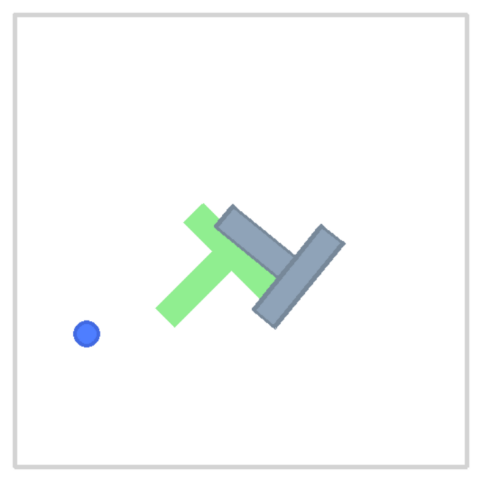

In [15]:
import gymnasium as gym
import gym_pusht
import matplotlib.pyplot as plt

env = gym.make(
    "gym_pusht/PushT-v0",
    obs_type="state",
    render_mode="rgb_array",
)

observation, info = env.reset(seed=42)

print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Initial observation:", observation)

plt.figure(figsize=(6, 6))
plt.imshow(env.render())
plt.axis("off")
plt.show()

### 1.1 Observation and Action Spaces

PushT uses a 5-dimensional state observation:

$$
o_t = [x_a, y_a, x_b, y_b, \theta_b]
$$

where:

- $(x_a, y_a)$ is the agent position.
- $(x_b, y_b)$ is the T-block position.
- $\theta_b$ is the T-block orientation.

The action is a 2D target position:

$$
a_t = [x_{\text{target}}, y_{\text{target}}]
$$

The environment uses a position controller to move the agent
toward the commanded target.

Unlike PointRobot, the block motion results from physical
contact rather than directly applying actions to the object.

Action: [200. 300.]
Observation before: [ 85.         359.         330.92444044 304.3775168    2.25313718]
Observation after:  [119.00225538 341.55536463 330.92444044 304.3775168    2.25313718]
Reward: 0.05975931325587878
Terminated: False
Truncated: False


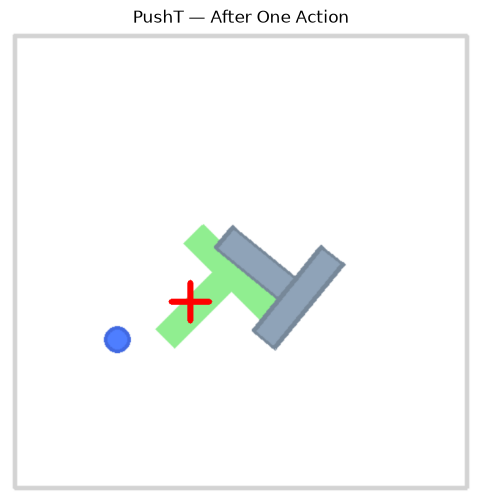

In [16]:
import numpy as np
import matplotlib.pyplot as plt

action = np.array([200.0, 300.0], dtype=np.float32)

observation_before = observation.copy()

observation, reward, terminated, truncated, info = env.step(action)

print("Action:", action)
print("Observation before:", observation_before)
print("Observation after: ", observation)
print("Reward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)

plt.figure(figsize=(6, 6))
plt.imshow(env.render())
plt.axis("off")
plt.title("PushT — After One Action")
plt.show()

Action is a 2D target in the "world space" (absolute coordinates). The environment uses a position controller to move the agent
toward the commanded target, but one step can be not enough to reach the desired position.

Reward is overlap between grey block and green block (target).

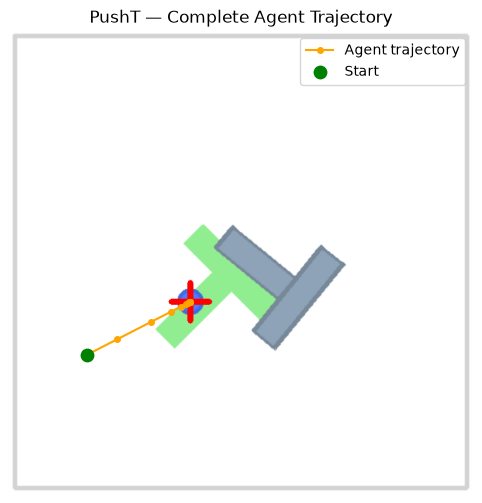

In [ ]:
observation, info = env.reset(seed=42)

action = np.array([200.0, 300.0], dtype=np.float32)

positions = [observation[:2].copy()]

for _ in range(11):
    observation, reward, terminated, truncated, info = env.step(action)
    positions.append(observation[:2].copy())

positions = np.array(positions)

plt.figure(figsize=(6, 6))

# Use extent to set the axes limits to match the environment's coordinate system
plt.imshow(
    env.render(),
    extent=[0, 512, 512, 0],
)

plt.plot(
    positions[:, 0],
    positions[:, 1],
    "o-",
    color="orange",
    markersize=4,
    label="Agent trajectory",
)

plt.scatter(
    positions[0, 0],
    positions[0, 1],
    color="green",
    s=80,
    label="Start",
    zorder=5,
)

plt.xlim(0, 512)
plt.ylim(512, 0)
plt.axis("off")
plt.legend()
plt.title("PushT — Complete Agent Trajectory")
plt.show()

### 1.2 Physical Interaction

Unlike PointRobot, PushT includes contact dynamics.

The agent does not directly control the T-block. Instead,
it moves toward a target position and interacts with the
block through physical contact.

We will execute a sequence of position commands and observe:

- Agent motion.
- Block translation and rotation.
- Reward changes.
- Contact events.

Initial block position: [330.92444044 304.3775168 ]
Final block position:   [380.62610423 285.97414552]
Block displacement:     [ 49.70166378 -18.40337128]
Final reward: 0.0158594276088849


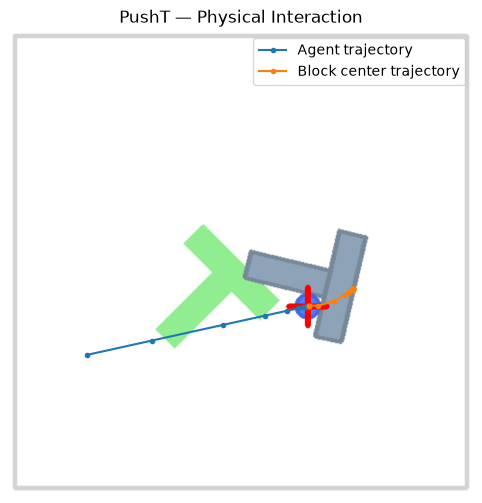

In [21]:
observation, info = env.reset(seed=42)

# Move the agent toward the T-block
action = np.array([330.0, 305.0], dtype=np.float32)

agent_positions = [observation[:2].copy()]
block_positions = [observation[2:4].copy()]
rewards = []

for _ in range(20):
    observation, reward, terminated, truncated, info = env.step(action)

    agent_positions.append(observation[:2].copy())
    block_positions.append(observation[2:4].copy())
    rewards.append(reward)

    if terminated or truncated:
        break

agent_positions = np.array(agent_positions)
block_positions = np.array(block_positions)

print("Initial block position:", block_positions[0])
print("Final block position:  ", block_positions[-1])
print("Block displacement:    ", block_positions[-1] - block_positions[0])
print("Final reward:", rewards[-1])

plt.figure(figsize=(6, 6))
plt.imshow(env.render(), extent=[0, 512, 512, 0])

plt.plot(
    agent_positions[:, 0],
    agent_positions[:, 1],
    "o-",
    markersize=3,
    label="Agent trajectory",
)

plt.plot(
    block_positions[:, 0],
    block_positions[:, 1],
    "o-",
    markersize=3,
    label="Block center trajectory",
)

plt.xlim(0, 512)
plt.ylim(512, 0)
plt.legend()
plt.axis("off")
plt.title("PushT — Physical Interaction")
plt.show()

### 1.3 Visualizing Contact Dynamics

In PushT, the environment state evolves according to physical
contact between the agent and the T-shaped object.

A single position command may produce:

- Free-space motion before contact.
- Translation of the block.
- Rotation of the block.
- Changes in reward as the block approaches or moves away
  from the target configuration.

We visualize several simulation frames to understand how
the same action produces different effects over time.

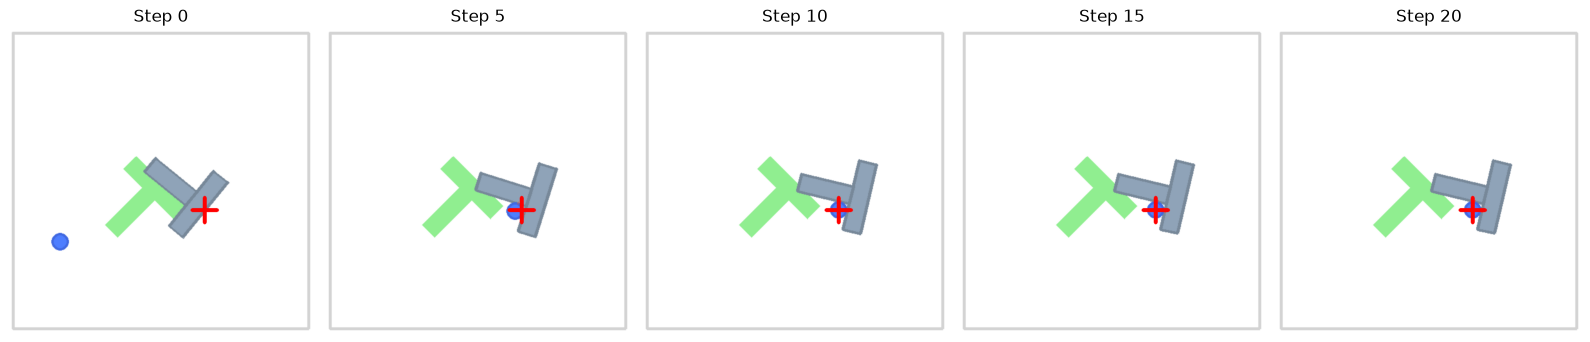

In [22]:
observation, info = env.reset(seed=42)

action = np.array([330.0, 305.0], dtype=np.float32)

frames = [env.render()]
observations = [observation.copy()]
rewards = []

for t in range(20):
    observation, reward, terminated, truncated, info = env.step(action)

    frames.append(env.render())
    observations.append(observation.copy())
    rewards.append(reward)

    if terminated or truncated:
        break

# Show snapshots from the episode
indices = np.linspace(0, len(frames) - 1, 5, dtype=int)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, idx in zip(axes, indices):
    ax.imshow(frames[idx])
    ax.set_title(f"Step {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Expert Demonstrations

In imitation learning, a dataset contains trajectories generated
by an expert policy or a human demonstrator.

A demonstration can be represented as:

$$
\tau = \{(o_t, a_t)\}_{t=0}^{T-1}
$$

where:

- $o_t$ is the observation at time $t$.
- $a_t$ is the expert action at time $t$.
- $T$ is the episode length.

Unlike our synthetic PointRobot demonstrations, PushT
demonstrations contain actions that interact with an object
through contact dynamics.

We will inspect a standard dataset before using it for
Behavior Cloning and Transformer-based policies.

### 2.1 Loading the PushT Dataset

We use the public PushT dataset distributed through LeRobot.

The dataset contains expert demonstrations consisting of
observations and actions recorded over multiple episodes.

Our first objective is to inspect:

- Number of episodes and frames.
- Dataset frequency (FPS).
- Available observation modalities.
- Action representation.

Understanding the dataset structure is essential before
building training samples for Behavior Cloning or ACT.

In [1]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset

dataset = LeRobotDataset("lerobot/pusht")

print("Total frames:", len(dataset))
print("Total episodes:", dataset.meta.total_episodes)
print("FPS:", dataset.meta.fps)

print("\nDataset features:")
for name, spec in dataset.meta.features.items():
    print(f"{name}: {spec}")

/Users/terreran/Documents/ws-playground/robot-learning-playground/.pixi/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 8 files: 100%|██████████| 8/8 [00:01<00:00,  6.18it/s]

Total frames: 25650
Total episodes: 206
FPS: 10

Dataset features:
observation.image: {'dtype': 'video', 'shape': (96, 96, 3), 'names': ['height', 'width', 'channel'], 'video_info': {'video.fps': 10.0, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'has_audio': False}}
observation.state: {'dtype': 'float32', 'shape': (2,), 'names': {'motors': ['motor_0', 'motor_1']}, 'fps': 10.0}
action: {'dtype': 'float32', 'shape': (2,), 'names': {'motors': ['motor_0', 'motor_1']}, 'fps': 10.0}
episode_index: {'dtype': 'int64', 'shape': (1,), 'names': None, 'fps': 10.0}
frame_index: {'dtype': 'int64', 'shape': (1,), 'names': None, 'fps': 10.0}
timestamp: {'dtype': 'float32', 'shape': (1,), 'names': None, 'fps': 10.0}
next.reward: {'dtype': 'float32', 'shape': (1,), 'names': None, 'fps': 10.0}
next.done: {'dtype': 'bool', 'shape': (1,), 'names': None, 'fps': 10.0}
next.success: {'dtype': 'bool', 'shape': (1,), 'names': None, 'fps': 10.0}
index: {'dtype': 'int64', 'shape

### 2.2 Inspecting a Dataset Sample

The PushT dataset provides multimodal observations.

Unlike the simulator's full 5D state, the recorded
low-dimensional observation contains only the 2D agent state.

The dataset also includes an RGB image, which provides
information about the object and the target configuration.

We inspect a single sample to understand:

- Tensor shapes and data types.
- State and action values.
- Image representation.
- Episode and frame metadata.

In [2]:
sample = dataset[0]

for key, value in sample.items():
    if hasattr(value, "shape"):
        print(f"{key:22s} shape={tuple(value.shape)}, dtype={value.dtype}")
    else:
        print(f"{key:22s} {value}")

observation.image      shape=(3, 96, 96), dtype=torch.float32
observation.state      shape=(2,), dtype=torch.float32
action                 shape=(2,), dtype=torch.float32
episode_index          shape=(), dtype=torch.int64
frame_index            shape=(), dtype=torch.int64
timestamp              shape=(), dtype=torch.float32
next.reward            shape=(), dtype=torch.float32
next.done              shape=(), dtype=torch.bool
next.success           shape=(), dtype=torch.bool
index                  shape=(), dtype=torch.int64
task_index             shape=(), dtype=torch.int64
task                   Push the T-shaped block onto the T-shaped target.


Image shape: torch.Size([3, 96, 96])
Image range: 0.239215686917305 1.0
Agent state: tensor([222.,  97.])
Expert action: tensor([233.,  71.])


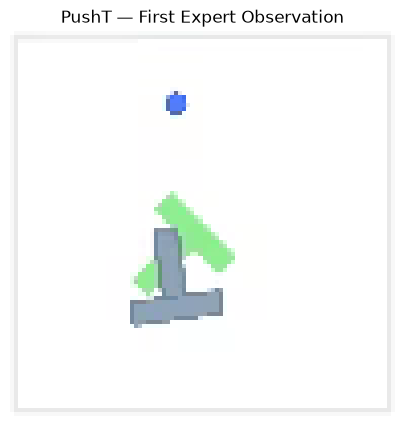

In [3]:
import matplotlib.pyplot as plt

image = sample["observation.image"]

print("Image shape:", image.shape)
print("Image range:", image.min().item(), image.max().item())

print("Agent state:", sample["observation.state"])
print("Expert action:", sample["action"])

plt.figure(figsize=(5, 5))
plt.imshow(image.permute(1, 2, 0).cpu().numpy())
plt.axis("off")
plt.title("PushT — First Expert Observation")
plt.show()

### 2.3 Reconstructing an Expert Episode

A demonstration is a temporally ordered sequence of observations
and expert actions.

We select one episode and inspect how the agent moves over time.

We distinguish:

- Observed agent positions.
- Expert position commands.
- Episode rewards.
- Episode duration.

This will help us understand the temporal structure of the
training data before introducing action chunks.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

episode_id = 0

# Find all dataset frames belonging to the selected episode
episode_indices = [
    i for i in range(len(dataset))
    if int(dataset[i]["episode_index"].item()) == episode_id
]

episode = [dataset[i] for i in episode_indices]

agent_states = np.stack([
    frame["observation.state"].numpy()
    for frame in episode
])

expert_actions = np.stack([
    frame["action"].numpy()
    for frame in episode
])

rewards = np.array([
    frame["next.reward"].item()
    for frame in episode
])

timestamps = np.array([
    frame["timestamp"].item()
    for frame in episode
])

print("Episode:", episode_id)
print("Frames:", len(episode))
print("Duration:", timestamps[-1] - timestamps[0], "seconds")
print("Initial agent position:", agent_states[0])
print("Final agent position:", agent_states[-1])
print("Final reward:", rewards[-1])


Episode: 0
Frames: 161
Duration: 16.0 seconds
Initial agent position: [222.  97.]
Final agent position: [158.33017 360.7482 ]
Final reward: 0.8732566833496094


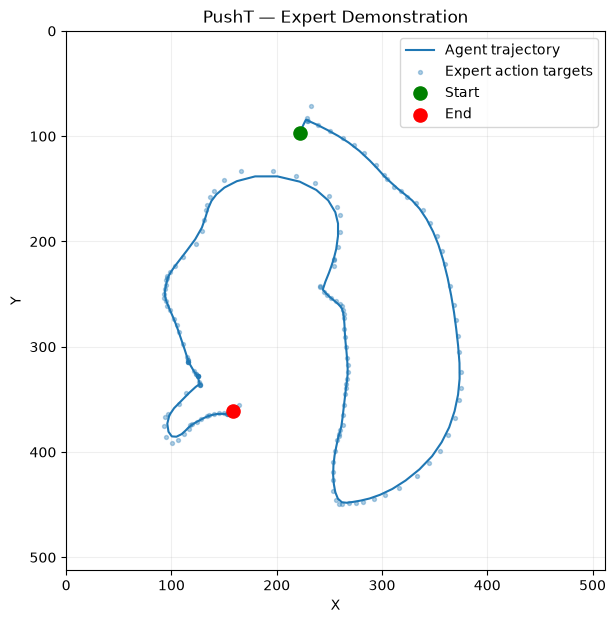

In [5]:
plt.figure(figsize=(7, 7))

plt.plot(
    agent_states[:, 0],
    agent_states[:, 1],
    "-",
    label="Agent trajectory",
)

plt.scatter(
    expert_actions[:, 0],
    expert_actions[:, 1],
    s=8,
    alpha=0.35,
    label="Expert action targets",
)

plt.scatter(
    agent_states[0, 0],
    agent_states[0, 1],
    color="green",
    s=90,
    label="Start",
    zorder=5,
)

plt.scatter(
    agent_states[-1, 0],
    agent_states[-1, 1],
    color="red",
    s=90,
    label="End",
    zorder=5,
)

plt.xlim(0, 512)
plt.ylim(512, 0)
plt.gca().set_aspect("equal")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("PushT — Expert Demonstration")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 2.4 Visualizing an Expert Demonstration

The agent trajectory alone does not fully describe the task.

PushT requires manipulating the position and orientation
of an object through physical contact.

We visualize snapshots from an expert demonstration to observe:

- How the agent approaches the object.
- When the agent interacts with the object.
- How the object translates and rotates.
- Whether the final configuration matches the target.

This illustrates why visual observations are important
for visuomotor imitation learning.

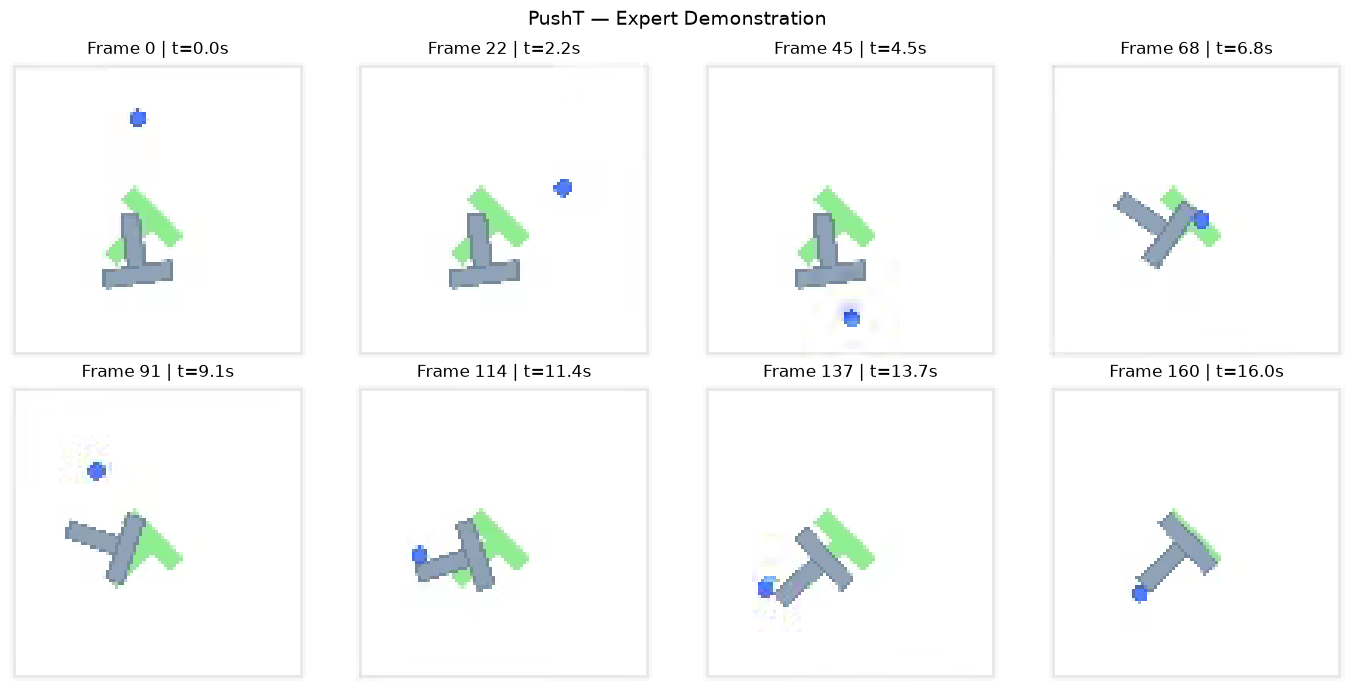

In [6]:
# Select 8 uniformly spaced frames from the demonstration
frame_ids = np.linspace(
    0, len(episode) - 1, 8, dtype=int
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, idx in zip(axes.flat, frame_ids):
    image = episode[idx]["observation.image"]

    ax.imshow(image.permute(1, 2, 0).cpu().numpy())
    ax.set_title(
        f"Frame {idx} | t={timestamps[idx]:.1f}s"
    )
    ax.axis("off")

plt.suptitle("PushT — Expert Demonstration", fontsize=14)
plt.tight_layout()
plt.show()

### 2.5 Episode Rewards and Success

A successful manipulation requires the T-block to reach
the desired target configuration.

We inspect the reward and success signals throughout
the expert demonstration.

This allows us to distinguish visual progress toward the
goal from the environment's actual success criterion.

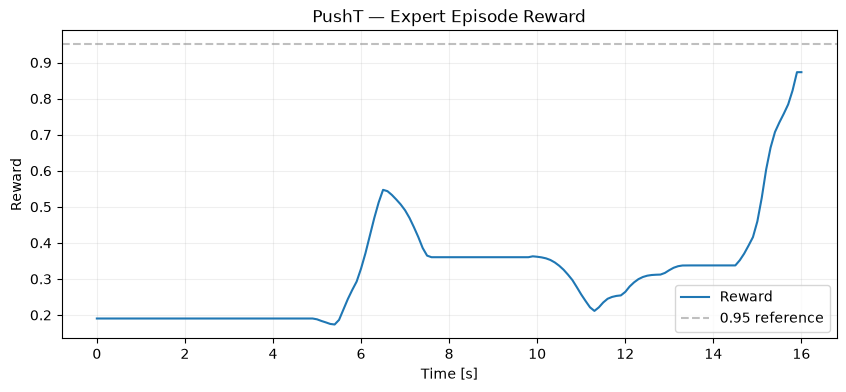

Maximum reward: 0.8732566833496094
Final reward: 0.8732566833496094
Any success: False
Final success: False
Final done: True


In [7]:
success = np.array([
    frame["next.success"].item()
    for frame in episode
])

done = np.array([
    frame["next.done"].item()
    for frame in episode
])

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(timestamps, rewards, label="Reward")
ax.axhline(0.95, color="gray", linestyle="--",
           alpha=0.5, label="0.95 reference")

ax.set_xlabel("Time [s]")
ax.set_ylabel("Reward")
ax.set_title("PushT — Expert Episode Reward")
ax.grid(alpha=0.2)
ax.legend()

plt.show()

print("Maximum reward:", rewards.max())
print("Final reward:", rewards[-1])
print("Any success:", success.any())
print("Final success:", success[-1])
print("Final done:", done[-1])

## 3. Preparing Action Chunks

Action chunking transforms a sequence of expert actions into
fixed-horizon training targets.

For a chunk horizon $H$, the training sample is:

$$
(o_t, A_t)
$$

where:

$$
A_t = [a_t, a_{t+1}, \ldots, a_{t+H-1}]
$$

In PushT, each action is a 2D target position.

Therefore, an action chunk has shape:

$$
A_t \in \mathbb{R}^{H \times 2}
$$

With $H=8$ and a dataset frequency of 10 Hz, each chunk
represents 0.8 seconds of expert action commands.

We first extract chunks from a single demonstration,
without crossing episode boundaries.

In [9]:
H = 8

observations = []
action_chunks = []

for t in range(len(episode) - H + 1):
    observations.append(agent_states[t])
    action_chunks.append(expert_actions[t:t + H])

observations = np.stack(observations)
action_chunks = np.stack(action_chunks)

print("Observations:", observations.shape)
print("Action chunks:", action_chunks.shape)

# Recall epidode has 161 frames, H=8, so we should have 161-8+1=154 samples

Observations: (154, 2)
Action chunks: (154, 8, 2)


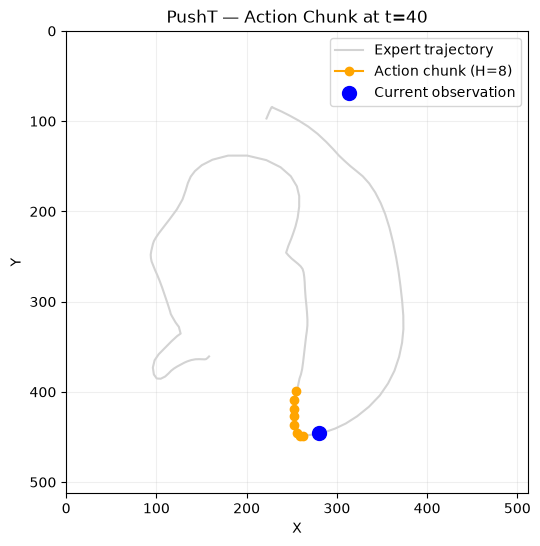

In [10]:
t = 40

chunk = action_chunks[t]
current_position = observations[t]

plt.figure(figsize=(6, 6))

plt.plot(
    agent_states[:, 0],
    agent_states[:, 1],
    color="lightgray",
    label="Expert trajectory",
)

plt.plot(
    chunk[:, 0],
    chunk[:, 1],
    "o-",
    color="orange",
    label="Action chunk (H=8)",
)

plt.scatter(
    current_position[0],
    current_position[1],
    color="blue",
    s=100,
    label="Current observation",
    zorder=5,
)

plt.xlim(0, 512)
plt.ylim(512, 0)
plt.gca().set_aspect("equal")
plt.xlabel("X")
plt.ylabel("Y")
plt.title(f"PushT — Action Chunk at t={t}")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Action chunks represent short segments of expert behavior.

Their direction and structure depend on the current phase
of the manipulation task.

We compare chunks extracted at different timestamps to
observe how the expert changes its commanded motion.

Each chunk contains 8 future target positions, corresponding
to 0.8 seconds at 10 Hz.

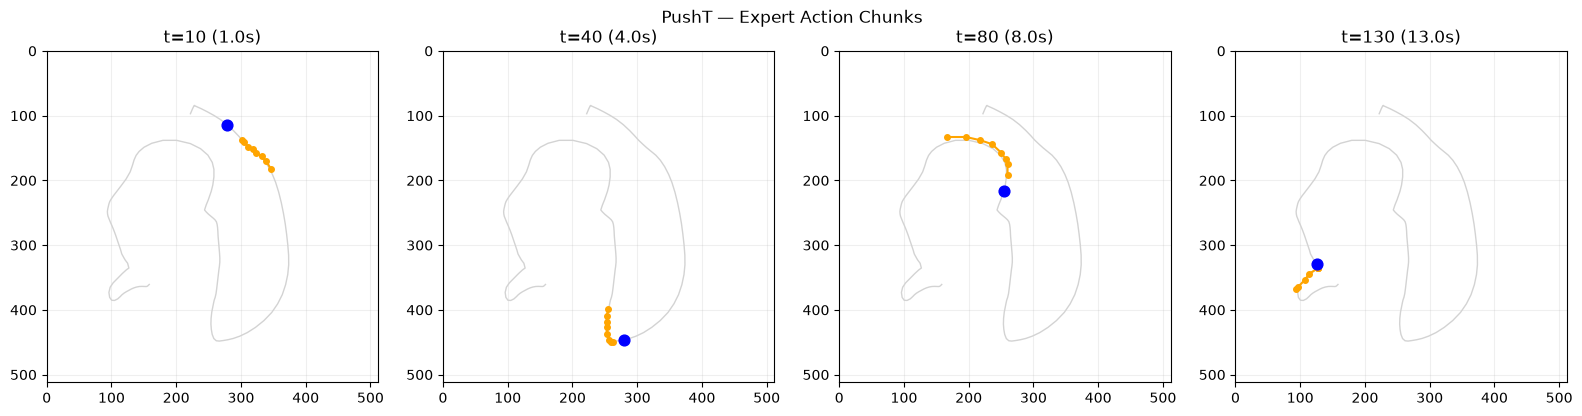

In [11]:
selected_times = [10, 40, 80, 130]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, t in zip(axes, selected_times):
    chunk = action_chunks[t]
    current_position = observations[t]

    ax.plot(
        agent_states[:, 0],
        agent_states[:, 1],
        color="lightgray",
        linewidth=1,
    )

    ax.plot(
        chunk[:, 0],
        chunk[:, 1],
        "o-",
        color="orange",
        markersize=4,
    )

    ax.scatter(
        current_position[0],
        current_position[1],
        color="blue",
        s=60,
        zorder=5,
    )

    ax.set_xlim(0, 512)
    ax.set_ylim(512, 0)
    ax.set_aspect("equal")
    ax.set_title(f"t={t} ({timestamps[t]:.1f}s)")
    ax.grid(alpha=0.2)

plt.suptitle("PushT — Expert Action Chunks")
plt.tight_layout()
plt.show()

## 4. Conclusions

In this notebook, we explored PushT as a standard benchmark
for visuomotor imitation learning.

### Key takeaways

**1. Position control**

Actions represent target positions for the agent, not
displacements or directly imposed states.

The actual motion depends on the environment's controller
and physical dynamics.

**2. Contact dynamics**

The agent manipulates the T-shaped object indirectly,
through physical contact.

Successful manipulation requires coordinated movements
that depend on the object's position and orientation.

**3. Multimodal observations**

The LeRobot PushT dataset provides:

- RGB images (3 × 96 × 96).
- Agent state (2D).
- Expert actions (2D).
- Episode metadata, rewards, and success signals.

The agent state alone does not describe the object's
configuration, making visual observations essential.

**4. Expert demonstrations**

Demonstrations contain complex trajectories involving
approach, repositioning, contact, pushing, and rotation.

An expert demonstration does not necessarily end in success.

**5. Action chunking**

We extracted action chunks of horizon H=8, corresponding
to 0.8 seconds of expert commands at 10 Hz.

Action chunks represent future control targets, not
the actual future trajectory of the agent.

### Next: Learning Policies on PushT

In the next notebook, we will build visuomotor imitation
learning policies using the PushT dataset.

We will start with a simple Behavior Cloning baseline,
then introduce action chunking and ACT.

The objective is to understand how visual information
and temporal action prediction affect closed-loop behavior.